In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import copy

from rdkit import Chem, RDLogger
from rdkit.Chem import AllChem, DataStructs
RDLogger.DisableLog('rdApp.*')

from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.metrics import (roc_auc_score, matthews_corrcoef, confusion_matrix,
                              roc_curve, average_precision_score, f1_score,
                              precision_recall_curve)

import torch, torch.nn as nn, torch.nn.functional as F
from torch_geometric.nn import TransformerConv, GINEConv, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import get_laplacian, to_dense_adj, degree as pyg_degree

SEED     = 42
BASE     = '/Users/yaminichitikela/Desktop/qsar casepase'
DEVICE   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
HIDDEN   = 256
N_LAYERS = 4
PE_DIM   = 8
BOND_DIM = 6

np.random.seed(SEED); torch.manual_seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark     = False
print(f'Device: {DEVICE}')

Device: cpu


In [2]:
def canonicalize(smi):
    try:
        mol = Chem.MolFromSmiles(str(smi))
        return Chem.MolToSmiles(mol) if mol else None
    except:
        return None

gold_df = pd.read_csv(f'{BASE}/liver/DILI_Goldstandard_1111.csv')
gold_df['csmi'] = gold_df['smiles_r'].apply(canonicalize)
gold_smiles = set(gold_df['csmi'].dropna())
print(f'Gold Standard 1111: {len(gold_smiles):,} compounds')

held_df = pd.read_csv(f'{BASE}/liver/test_data_heldouttest_DILIst_223.csv',
                      usecols=['smiles_r', 'TOXICITY'])
held_df['csmi'] = held_df['smiles_r'].apply(canonicalize)
held_df = (held_df.dropna(subset=['csmi'])
                  .drop_duplicates('csmi')
                  .reset_index(drop=True)
                  [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
held_smiles = set(held_df['csmi'])
print(f'Held-223 : {len(held_df):,}  DILI+={held_df.label.sum():,}  DILI-={(held_df.label==0).sum():,}')

all_raw = pd.read_csv(f'{BASE}/liver/Alloriginaldata_19911.csv',
                      usecols=['smiles_r', 'TOXICITY'])
all_raw['csmi'] = all_raw['smiles_r'].apply(canonicalize)
all_raw = all_raw.dropna(subset=['csmi']).drop_duplicates('csmi').reset_index(drop=True)

clin_df = (all_raw[~all_raw['csmi'].isin(gold_smiles)]
           .reset_index(drop=True)
           [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
print(f'Clinical (Alloriginal - Gold-1111): {len(clin_df):,}  '
      f'DILI+={clin_df.label.sum():,}  DILI-={(clin_df.label==0).sum():,}')

ncv_df = pd.read_csv(f'{BASE}/liver/test_data_ncv_DILIst_888.csv',
                     usecols=['smiles_r', 'TOXICITY'])
ncv_df['csmi'] = ncv_df['smiles_r'].apply(canonicalize)
ncv_df = (ncv_df.dropna(subset=['csmi'])
                .drop_duplicates('csmi')
                .reset_index(drop=True)
                [['csmi', 'TOXICITY']].rename(columns={'TOXICITY': 'label'}))
print(f'NCV-888  : {len(ncv_df):,}  DILI+={ncv_df.label.sum():,}  DILI-={(ncv_df.label==0).sum():,}')

print(f'\nNCV-888 intersect clinical (expected 0): {ncv_df["csmi"].isin(set(clin_df["csmi"])).sum()}')
print(f'NCV-888 intersect held-223  (expected 0): {ncv_df["csmi"].isin(held_smiles).sum()}')

Gold Standard 1111: 1,096 compounds
Held-223 : 222  DILI+=155  DILI-=67
Clinical (Alloriginal - Gold-1111): 12,900  DILI+=4,217  DILI-=8,683
NCV-888  : 874  DILI+=553  DILI-=321

NCV-888 intersect clinical (expected 0): 0
NCV-888 intersect held-223  (expected 0): 0


In [3]:
ATOM_SYMBOLS = [6, 7, 8, 16, 9, 15, 17, 35, 53]

def one_hot(val, choices):
    v = [0] * len(choices)
    try: v[choices.index(val)] = 1
    except ValueError: pass
    return v

def atom_features(atom):
    return (one_hot(atom.GetAtomicNum(), ATOM_SYMBOLS) + [1]
            + one_hot(atom.GetDegree(), [0,1,2,3,4,5])
            + [atom.GetFormalCharge()]
            + one_hot(int(atom.GetHybridization()), [2,3,4,5])
            + [int(atom.GetIsAromatic()), int(atom.IsInRing())])

def bond_features(bond):
    bt = bond.GetBondTypeAsDouble()
    return [bt==1.0, bt==1.5, bt==2.0, bt==3.0,
            int(bond.GetIsConjugated()), int(bond.IsInRing())]

def mol_to_graph(smi, label):
    mol = Chem.MolFromSmiles(smi)
    if mol is None: return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    if mol.GetNumBonds() == 0:
        edge_index = torch.zeros((2,0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    else:
        edges, attrs = [], []
        for b in mol.GetBonds():
            i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
            bf = bond_features(b)
            edges += [[i,j],[j,i]]; attrs += [bf,bf]
        edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(attrs, dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([label], dtype=torch.float))

ATOM_DIM = len(atom_features(Chem.MolFromSmiles('C').GetAtomWithIdx(0)))

def build_graphs(df, name):
    graphs_raw = [mol_to_graph(smi, int(lbl)) for smi, lbl in zip(df['csmi'], df['label'])]
    g_ok   = [g is not None for g in graphs_raw]
    graphs = [g for g, v in zip(graphs_raw, g_ok) if v]
    df     = df[g_ok].reset_index(drop=True)
    y      = df['label'].values.astype(int)
    print(f'{name}: {len(df):,}  DILI+={int(y.sum()):,}  DILI-={int((y==0).sum()):,}')
    return df, y, graphs

print(f'Atom dim: {ATOM_DIM}, Bond dim: {BOND_DIM}')

Atom dim: 23, Bond dim: 6


In [4]:
print('Building graph features...')
clin_df, y_clin, clin_graphs = build_graphs(clin_df, 'Clinical')
ncv_df,  y_ncv,  ncv_graphs  = build_graphs(ncv_df,  'NCV-888')
held_df, y_held, held_graphs = build_graphs(held_df, 'Held-out-223')
held_loader = DataLoader(held_graphs, batch_size=64)
print('Done.')

Building graph features...
Clinical: 12,900  DILI+=4,217  DILI-=8,683
NCV-888: 874  DILI+=553  DILI-=321
Held-out-223: 222  DILI+=155  DILI-=67
Done.


In [5]:
idx_c = np.arange(len(y_clin))
idx_c_pool, _ = train_test_split(idx_c, test_size=0.10, stratify=y_clin, random_state=SEED)
idx_c_tr, idx_c_va = train_test_split(
    idx_c_pool, test_size=0.10/0.90, stratify=y_clin[idx_c_pool], random_state=SEED)

y_c_tr = y_clin[idx_c_tr]
y_c_va = y_clin[idx_c_va]
g_c_tr = [clin_graphs[i] for i in idx_c_tr]
g_c_va = [clin_graphs[i] for i in idx_c_va]

clin_tr_ld = DataLoader(g_c_tr, batch_size=64, shuffle=True)
clin_va_ld = DataLoader(g_c_va, batch_size=64)
print(f'Clinical train / val : {len(idx_c_tr):,} / {len(idx_c_va):,}')

y_aug_gt  = np.concatenate([y_c_tr, y_ncv])
g_aug_tr  = g_c_tr + ncv_graphs
aug_tr_ld = DataLoader(g_aug_tr, batch_size=64, shuffle=True)

pos_w_clin = torch.tensor([(y_c_tr==0).sum() / max((y_c_tr==1).sum(),1)],
                           dtype=torch.float).to(DEVICE)
pos_w_aug  = torch.tensor([(y_aug_gt==0).sum() / max((y_aug_gt==1).sum(),1)],
                           dtype=torch.float).to(DEVICE)
crit_clin  = nn.BCEWithLogitsLoss(pos_weight=pos_w_clin)
crit_aug   = nn.BCEWithLogitsLoss(pos_weight=pos_w_aug)
print(f'pos_weight  Stage-1={pos_w_clin.item():.3f}  Stage-2={pos_w_aug.item():.3f}')
print(f'NCV-888 aug train   : {len(g_aug_tr):,}')

Clinical train / val : 10,320 / 1,290
pos_weight  Stage-1=2.060  Stage-2=1.851
NCV-888 aug train   : 11,194


In [6]:
p_rf_clin  = np.load(f'{BASE}/liver/p_rf_clin.npy')
p_rf_aug   = np.load(f'{BASE}/liver/p_rf_aug.npy')
p_xgb_clin = np.load(f'{BASE}/liver/p_xgb_clin.npy')
p_xgb_aug  = np.load(f'{BASE}/liver/p_xgb_aug.npy')
print('RF / XGB probabilities loaded from saved .npy files.')
print(f'Held-out test: DILI+={int(y_held.sum())}  DILI-={int((y_held==0).sum())}')

RF / XGB probabilities loaded from saved .npy files.
Held-out test: DILI+=155  DILI-=67


In [7]:
METRIC_COLS = ['Model','Sensitivity','Specificity','CCR','ROC-AUC','PR-AUC','MCC','F1']

def evaluate(y_true, y_prob, name, cpt=0.5):
    y_pred = (y_prob >= cpt).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    sens = tp / max(tp+fn,1) * 100
    spec = tn / max(tn+fp,1) * 100
    return {'Model':name, 'Sensitivity':sens, 'Specificity':spec,
            'CCR':(sens+spec)/2, 'ROC-AUC':roc_auc_score(y_true,y_prob),
            'PR-AUC':average_precision_score(y_true,y_prob),
            'MCC':matthews_corrcoef(y_true,y_pred),
            'F1':f1_score(y_true,y_pred,zero_division=0)}

def get_probs(encoder, head, loader, device):
    encoder.eval(); head.eval()
    probs, labels = [], []
    with torch.no_grad():
        for batch in loader:
            batch = batch.to(device)
            probs.extend(torch.sigmoid(head(encoder(batch))).cpu().numpy())
            labels.extend(batch.y.cpu().numpy())
    return np.array(probs), np.array(labels)

def train_one_epoch(encoder, head, loader, optimizer, criterion, device):
    encoder.train(); head.train()
    for batch in loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        criterion(head(encoder(batch)), batch.y).backward()
        optimizer.step()

def train_gt_model(encoder, head, train_ld, val_ld, criterion,
                   max_epochs=100, patience=20, lr=1e-3, label=''):
    """Early stopping on combined 0.5*ROC-AUC + 0.5*F1."""
    opt   = torch.optim.Adam(
        list(encoder.parameters()) + list(head.parameters()), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=5, factor=0.5)
    best  = {'score':0.0, 'enc':None, 'head':None}
    no_imp = 0
    for ep in range(max_epochs):
        train_one_epoch(encoder, head, train_ld, opt, criterion, DEVICE)
        va_p, va_l = get_probs(encoder, head, val_ld, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)
        va_f1  = f1_score(va_l, (va_p >= 0.5).astype(int), zero_division=0)
        combined = 0.5 * va_auc + 0.5 * va_f1
        sched.step(1 - combined)
        if combined > best['score']:
            best['score'] = combined
            best['enc']   = copy.deepcopy(encoder.state_dict())
            best['head']  = copy.deepcopy(head.state_dict())
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                if label:
                    print(f'  [{label}] early stop ep {ep+1}  best={best["score"]:.4f}')
                break
        if label and (ep+1) % 20 == 0:
            print(f'  [{label}] ep {ep+1:3d}  auc={va_auc:.4f}  f1={va_f1:.4f}  '
                  f'combined={combined:.4f}  best={best["score"]:.4f}')
    encoder.load_state_dict(best['enc'])
    head.load_state_dict(best['head'])
    return best['score']

print('train_gt_model: early stopping on 0.5*ROC-AUC + 0.5*F1')

train_gt_model: early stopping on 0.5*ROC-AUC + 0.5*F1


In [8]:
class ClassHead(nn.Module):
    def __init__(self, hidden=256, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(hidden, hidden//2), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(hidden//2, 1))
    def forward(self, h):
        return self.net(h).squeeze(-1)

class GraphormerEncoder(nn.Module):
    def __init__(self, in_dim, hidden=256, n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        head_dim = hidden // n_heads
        self.input_proj = nn.Linear(in_dim, hidden)
        self.degree_emb = nn.Embedding(100, hidden)
        self.convs = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            self.convs.append(TransformerConv(hidden, head_dim, heads=n_heads,
                                              edge_dim=BOND_DIM, concat=True,
                                              dropout=dropout, beta=True))
            self.bns.append(nn.LayerNorm(hidden))

    def forward(self, data):
        x, ei, ea, batch = data.x, data.edge_index, data.edge_attr, data.batch
        h   = self.input_proj(x)
        deg = pyg_degree(ei[0], num_nodes=x.size(0)).long().clamp(max=99)
        h   = torch.nn.functional.relu(h + self.degree_emb(deg))
        for conv, bn in zip(self.convs, self.bns):
            h = bn(torch.nn.functional.gelu(conv(h, ei, ea)))
            h = torch.nn.functional.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

class GraphGPSEncoder(nn.Module):
    def __init__(self, in_dim, hidden=256, pe_dim=PE_DIM,
                 n_heads=4, n_layers=4, dropout=0.3):
        super().__init__()
        self.hidden = hidden; self.dropout = dropout
        assert hidden % n_heads == 0
        self.input_proj = nn.Linear(in_dim + pe_dim, hidden)
        self.convs = nn.ModuleList()
        self.attn  = nn.ModuleList()
        self.bns   = nn.ModuleList()
        for _ in range(n_layers):
            mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                nn.Linear(hidden, hidden))
            self.convs.append(GINEConv(mlp, edge_dim=BOND_DIM))
            self.attn.append(nn.MultiheadAttention(
                hidden, n_heads, dropout=dropout, batch_first=True))
            self.bns.append(nn.LayerNorm(hidden))

    def forward(self, data):
        from torch_geometric.utils import to_dense_batch
        x, ei, ea, batch, pe = (
            data.x, data.edge_index, data.edge_attr, data.batch, data.pe)
        h = self.input_proj(torch.cat([x, pe], dim=-1))
        for conv, attn, bn in zip(self.convs, self.attn, self.bns):
            h_local = conv(h, ei, ea)
            h_dense, mask = to_dense_batch(h, batch)
            h_global, _   = attn(h_dense, h_dense, h_dense, key_padding_mask=~mask)
            h_global = h_global[mask]
            h = bn(h + h_local + h_global)
            h = torch.nn.functional.dropout(h, p=self.dropout, training=self.training)
        return global_mean_pool(h, batch)

print('ClassHead, GraphormerEncoder, GraphGPSEncoder defined.')

ClassHead, GraphormerEncoder, GraphGPSEncoder defined.


In [9]:
def compute_laplacian_pe(data, k=PE_DIM):
    n = data.num_nodes
    if n <= 2: return torch.zeros(n, k)
    ei, ew = get_laplacian(data.edge_index, normalization='sym', num_nodes=n)
    L = to_dense_adj(ei, edge_attr=ew, max_num_nodes=n).squeeze(0).numpy()
    try:
        import numpy.linalg as nla
        _, vecs = nla.eigh(L)
        num_take = min(k, n-1)
        pe = torch.from_numpy(vecs[:, 1:1+num_take]).float()
        if pe.shape[1] < k:
            pe = torch.nn.functional.pad(pe, (0, k-pe.shape[1]))
    except Exception:
        pe = torch.zeros(n, k)
    return pe

def add_pe(graph_list, k=PE_DIM):
    return [Data(x=d.x, edge_index=d.edge_index, edge_attr=d.edge_attr,
                 y=d.y, pe=compute_laplacian_pe(d, k)) for d in graph_list]

print('Computing Laplacian PE for GraphGPS...')
gps_c_tr  = add_pe(g_c_tr)
gps_c_va  = add_pe(g_c_va)
gps_ncv   = add_pe(ncv_graphs)
gps_held  = add_pe(held_graphs)

gps_clin_tr_ld = DataLoader(gps_c_tr,         batch_size=64, shuffle=True)
gps_clin_va_ld = DataLoader(gps_c_va,         batch_size=64)
gps_aug_tr_ld  = DataLoader(gps_c_tr+gps_ncv, batch_size=64, shuffle=True)
gps_held_ld    = DataLoader(gps_held,          batch_size=64)

print(f'GPS train/val: {len(gps_c_tr):,} / {len(gps_c_va):,}')
print(f'GPS aug train: {len(gps_c_tr)+len(gps_ncv):,}')
print(f'GPS held    : {len(gps_held):,}')

Computing Laplacian PE for GraphGPS...
GPS train/val: 10,320 / 1,290
GPS aug train: 11,194
GPS held    : 222


In [10]:
GT_HP_GRID = [
    {'n_layers':nl, 'hidden':h, 'n_heads':h//64, 'dropout':dr}
    for nl in [4, 6, 8]
    for h  in [256, 512]
    for dr in [0.2, 0.3]
]
print(f'HP grid: {len(GT_HP_GRID)} configs per model')
for i, hp in enumerate(GT_HP_GRID):
    print(f'  [{i+1:2d}] {hp}')

def _search_graphormer(grid, tr_ld, va_ld, crit, max_epochs=25, patience=8, lr=1e-3):
    best_score, best_hp = 0.0, None
    for i, hp in enumerate(grid):
        nl, h, nh, dr = hp['n_layers'], hp['hidden'], hp['n_heads'], hp['dropout']
        enc  = GraphormerEncoder(ATOM_DIM, hidden=h, n_heads=nh,
                                  n_layers=nl, dropout=dr).to(DEVICE)
        head = ClassHead(hidden=h, dropout=dr).to(DEVICE)
        score = train_gt_model(enc, head, tr_ld, va_ld, crit,
                                max_epochs=max_epochs, patience=patience, lr=lr)
        tag = f'layers={nl} hidden={h} heads={nh} drop={dr}'
        print(f'  [{i+1:2d}/{len(grid)}] {tag}  combined={score:.4f}'
              + ('  *** BEST' if score > best_score else ''))
        if score > best_score:
            best_score, best_hp = score, hp
    print(f'\n  GRPH best: {best_hp}  combined={best_score:.4f}')
    return best_hp, best_score

def _search_graphgps(grid, tr_ld, va_ld, crit, max_epochs=25, patience=8, lr=1e-3):
    best_score, best_hp = 0.0, None
    for i, hp in enumerate(grid):
        nl, h, nh, dr = hp['n_layers'], hp['hidden'], hp['n_heads'], hp['dropout']
        enc  = GraphGPSEncoder(ATOM_DIM, hidden=h, pe_dim=PE_DIM,
                                n_heads=nh, n_layers=nl, dropout=dr).to(DEVICE)
        head = ClassHead(hidden=h, dropout=dr).to(DEVICE)
        score = train_gt_model(enc, head, tr_ld, va_ld, crit,
                                max_epochs=max_epochs, patience=patience, lr=lr)
        tag = f'layers={nl} hidden={h} heads={nh} drop={dr}'
        print(f'  [{i+1:2d}/{len(grid)}] {tag}  combined={score:.4f}'
              + ('  *** BEST' if score > best_score else ''))
        if score > best_score:
            best_score, best_hp = score, hp
    print(f'\n  GPS best: {best_hp}  combined={best_score:.4f}')
    return best_hp, best_score

print('\n=== HP Search: Graphormer (25 ep / patience 8) ===')
grph_best_hp, _ = _search_graphormer(GT_HP_GRID, clin_tr_ld, clin_va_ld, crit_clin)

print('\n=== HP Search: GraphGPS (25 ep / patience 8) ===')
gps_best_hp,  _ = _search_graphgps(GT_HP_GRID, gps_clin_tr_ld, gps_clin_va_ld, crit_clin)

HP grid: 12 configs per model
  [ 1] {'n_layers': 4, 'hidden': 256, 'n_heads': 4, 'dropout': 0.2}
  [ 2] {'n_layers': 4, 'hidden': 256, 'n_heads': 4, 'dropout': 0.3}
  [ 3] {'n_layers': 4, 'hidden': 512, 'n_heads': 8, 'dropout': 0.2}
  [ 4] {'n_layers': 4, 'hidden': 512, 'n_heads': 8, 'dropout': 0.3}
  [ 5] {'n_layers': 6, 'hidden': 256, 'n_heads': 4, 'dropout': 0.2}
  [ 6] {'n_layers': 6, 'hidden': 256, 'n_heads': 4, 'dropout': 0.3}
  [ 7] {'n_layers': 6, 'hidden': 512, 'n_heads': 8, 'dropout': 0.2}
  [ 8] {'n_layers': 6, 'hidden': 512, 'n_heads': 8, 'dropout': 0.3}
  [ 9] {'n_layers': 8, 'hidden': 256, 'n_heads': 4, 'dropout': 0.2}
  [10] {'n_layers': 8, 'hidden': 256, 'n_heads': 4, 'dropout': 0.3}
  [11] {'n_layers': 8, 'hidden': 512, 'n_heads': 8, 'dropout': 0.2}
  [12] {'n_layers': 8, 'hidden': 512, 'n_heads': 8, 'dropout': 0.3}

=== HP Search: Graphormer (25 ep / patience 8) ===
  [ 1/12] layers=4 hidden=256 heads=4 drop=0.2  combined=0.5865  *** BEST
  [ 2/12] layers=4 hidden=25

In [11]:
np.random.seed(SEED); torch.manual_seed(SEED)

# ── Graphormer ────────────────────────────────────────────────────────────────
nl, h, nh, dr = (grph_best_hp['n_layers'], grph_best_hp['hidden'],
                  grph_best_hp['n_heads'],  grph_best_hp['dropout'])
print(f'=== Graphormer best HP: layers={nl}  hidden={h}  heads={nh}  dropout={dr} ===')

grph_enc  = GraphormerEncoder(ATOM_DIM, hidden=h, n_heads=nh,
                               n_layers=nl, dropout=dr).to(DEVICE)
grph_head = ClassHead(hidden=h, dropout=dr).to(DEVICE)
print('Stage 1 (100 ep / patience 20)...')
train_gt_model(grph_enc, grph_head, clin_tr_ld, clin_va_ld, crit_clin,
               max_epochs=100, patience=20, lr=1e-3, label='GRPH-S1')
grph_s1_enc_w  = copy.deepcopy(grph_enc.state_dict())
grph_s1_head_w = copy.deepcopy(grph_head.state_dict())

p_grph_clin, _ = get_probs(grph_enc, grph_head, held_loader, DEVICE)
r = evaluate(y_held, p_grph_clin, 'Graphormer Stage-1')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  '
      f'Spec={r["Specificity"]:.1f}%  F1={r["F1"]:.4f}')

grph_enc2  = GraphormerEncoder(ATOM_DIM, hidden=h, n_heads=nh,
                                n_layers=nl, dropout=dr).to(DEVICE)
grph_head2 = ClassHead(hidden=h, dropout=dr).to(DEVICE)
grph_enc2.load_state_dict(grph_s1_enc_w)
grph_head2.load_state_dict(grph_s1_head_w)
print('Stage 2 (80 ep / patience 15)...')
train_gt_model(grph_enc2, grph_head2, aug_tr_ld, clin_va_ld, crit_aug,
               max_epochs=80, patience=15, lr=5e-4, label='GRPH-S2')

p_grph_aug, _ = get_probs(grph_enc2, grph_head2, held_loader, DEVICE)
r = evaluate(y_held, p_grph_aug, 'Graphormer Stage-2')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  '
      f'Spec={r["Specificity"]:.1f}%  F1={r["F1"]:.4f}')

# ── GraphGPS ──────────────────────────────────────────────────────────────────
nl, h, nh, dr = (gps_best_hp['n_layers'], gps_best_hp['hidden'],
                  gps_best_hp['n_heads'],  gps_best_hp['dropout'])
print(f'\n=== GraphGPS best HP: layers={nl}  hidden={h}  heads={nh}  dropout={dr} ===')

gps_enc  = GraphGPSEncoder(ATOM_DIM, hidden=h, pe_dim=PE_DIM,
                            n_heads=nh, n_layers=nl, dropout=dr).to(DEVICE)
gps_head = ClassHead(hidden=h, dropout=dr).to(DEVICE)
print('Stage 1 (100 ep / patience 20)...')
train_gt_model(gps_enc, gps_head, gps_clin_tr_ld, gps_clin_va_ld, crit_clin,
               max_epochs=100, patience=20, lr=1e-3, label='GPS-S1')
gps_s1_enc_w  = copy.deepcopy(gps_enc.state_dict())
gps_s1_head_w = copy.deepcopy(gps_head.state_dict())

p_gps_clin, _ = get_probs(gps_enc, gps_head, gps_held_ld, DEVICE)
r = evaluate(y_held, p_gps_clin, 'GraphGPS Stage-1')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  '
      f'Spec={r["Specificity"]:.1f}%  F1={r["F1"]:.4f}')

gps_enc2  = GraphGPSEncoder(ATOM_DIM, hidden=h, pe_dim=PE_DIM,
                             n_heads=nh, n_layers=nl, dropout=dr).to(DEVICE)
gps_head2 = ClassHead(hidden=h, dropout=dr).to(DEVICE)
gps_enc2.load_state_dict(gps_s1_enc_w)
gps_head2.load_state_dict(gps_s1_head_w)
print('Stage 2 (80 ep / patience 15)...')
train_gt_model(gps_enc2, gps_head2, gps_aug_tr_ld, gps_clin_va_ld, crit_aug,
               max_epochs=80, patience=15, lr=5e-4, label='GPS-S2')

p_gps_aug, _ = get_probs(gps_enc2, gps_head2, gps_held_ld, DEVICE)
r = evaluate(y_held, p_gps_aug, 'GraphGPS Stage-2')
print(f'  AUC={r["ROC-AUC"]:.4f}  Sens={r["Sensitivity"]:.1f}%  '
      f'Spec={r["Specificity"]:.1f}%  F1={r["F1"]:.4f}')

print('\np_grph_clin, p_grph_aug, p_gps_clin, p_gps_aug ready.')

=== Graphormer best HP: layers=4  hidden=512  heads=8  dropout=0.2 ===
Stage 1 (100 ep / patience 20)...
  [GRPH-S1] ep  20  auc=0.6154  f1=0.4887  combined=0.5521  best=0.5841
  [GRPH-S1] early stop ep 33  best=0.5841
  AUC=0.6007  Sens=80.0%  Spec=25.4%  F1=0.7538
Stage 2 (80 ep / patience 15)...
  [GRPH-S2] early stop ep 17  best=0.5885
  AUC=0.6099  Sens=79.4%  Spec=28.4%  F1=0.7546

=== GraphGPS best HP: layers=4  hidden=256  heads=4  dropout=0.2 ===
Stage 1 (100 ep / patience 20)...
  [GPS-S1] ep  20  auc=0.6404  f1=0.5054  combined=0.5729  best=0.5837
  [GPS-S1] early stop ep 23  best=0.5837
  AUC=0.6195  Sens=95.5%  Spec=6.0%  F1=0.8087
Stage 2 (80 ep / patience 15)...
  [GPS-S2] ep  20  auc=0.6860  f1=0.5108  combined=0.5984  best=0.6127
  [GPS-S2] ep  40  auc=0.6986  f1=0.5519  combined=0.6252  best=0.6306
  [GPS-S2] ep  60  auc=0.7127  f1=0.5453  combined=0.6290  best=0.6313
  [GPS-S2] early stop ep 66  best=0.6313
  AUC=0.6138  Sens=66.5%  Spec=47.8%  F1=0.7031

p_grph_clin

In [12]:
p_cons_classic_clin = np.mean([p_rf_clin,  p_xgb_clin],                     axis=0)
p_cons_classic_aug  = np.mean([p_rf_aug,   p_xgb_aug],                      axis=0)
p_cons_gt_clin      = np.mean([p_grph_clin, p_gps_clin],                    axis=0)
p_cons_gt_aug       = np.mean([p_grph_aug,  p_gps_aug],                     axis=0)
p_cons_full_clin    = np.mean([p_rf_clin,  p_xgb_clin, p_grph_clin, p_gps_clin], axis=0)
p_cons_full_aug     = np.mean([p_rf_aug,   p_xgb_aug,  p_grph_aug,  p_gps_aug],  axis=0)

model_rows = [
    ('RF          Stage-1  (Clinical)',                               p_rf_clin),
    ('RF          Stage-2  (Clinical + NCV-888)',                     p_rf_aug),
    ('XGB         Stage-1  (Clinical)',                               p_xgb_clin),
    ('XGB         Stage-2  (Clinical + NCV-888)',                     p_xgb_aug),
    ('Graphormer  Stage-1  (Clinical)',                               p_grph_clin),
    ('Graphormer  Stage-2  (Clinical + NCV-888)',                     p_grph_aug),
    ('GraphGPS    Stage-1  (Clinical)',                               p_gps_clin),
    ('GraphGPS    Stage-2  (Clinical + NCV-888)',                     p_gps_aug),
    ('Consensus Classic  Stage-1  (RF+XGB, Clinical)',                p_cons_classic_clin),
    ('Consensus GT       Stage-1  (Graphormer+GPS, Clinical)',        p_cons_gt_clin),
    ('Consensus Classic  Stage-2  (RF+XGB, Clinical+NCV)',            p_cons_classic_aug),
    ('Consensus GT       Stage-2  (Graphormer+GPS, Clinical+NCV)',    p_cons_gt_aug),
    ('Consensus Full     Stage-1  (all models, Clinical)',            p_cons_full_clin),
    ('Consensus Full     Stage-2  (all models, Clinical+NCV)',        p_cons_full_aug),
]

all_results = [evaluate(y_held, prob, name) for name, prob in model_rows]
df_table    = pd.DataFrame(all_results)

W = 58
print('=== Results on Held-out 222 ===')
print(f'{"Model":<{W}}  {"Sens":>5}  {"Spec":>5}  {"CCR":>5}  {"AUC":>6}  {"PR-AUC":>6}  {"MCC":>6}  {"F1":>5}')
print('-' * (W + 54))
for _, row in df_table.iterrows():
    print(f'{row["Model"]:<{W}}  {row["Sensitivity"]:>4.1f}%  {row["Specificity"]:>4.1f}%  '
          f'{row["CCR"]:>4.1f}%  {row["ROC-AUC"]:>6.4f}  {row["PR-AUC"]:>6.4f}  '
          f'{row["MCC"]:>6.4f}  {row["F1"]:>5.4f}')

df_table.to_csv(f'{BASE}/liver/table6_results.csv', index=False)
print('\nSaved -> liver/table6_results.csv')

=== Results on Held-out 222 ===
Model                                                        Sens   Spec    CCR     AUC  PR-AUC     MCC     F1
----------------------------------------------------------------------------------------------------------------
RF          Stage-1  (Clinical)                             52.3%  77.6%  64.9%  0.6711  0.8138  0.2768  0.6454
RF          Stage-2  (Clinical + NCV-888)                   53.5%  74.6%  64.1%  0.6855  0.8222  0.2600  0.6510
XGB         Stage-1  (Clinical)                             65.2%  61.2%  63.2%  0.6580  0.8057  0.2445  0.7163
XGB         Stage-2  (Clinical + NCV-888)                   65.8%  64.2%  65.0%  0.6738  0.8278  0.2778  0.7260
Graphormer  Stage-1  (Clinical)                             80.0%  25.4%  52.7%  0.6007  0.7539  0.0599  0.7538
Graphormer  Stage-2  (Clinical + NCV-888)                   79.4%  28.4%  53.9%  0.6099  0.7605  0.0842  0.7546
GraphGPS    Stage-1  (Clinical)                             95.5%   6.0%

In [13]:
np.save(f'{BASE}/liver/p_grph_clin.npy', p_grph_clin)
np.save(f'{BASE}/liver/p_grph_aug.npy',  p_grph_aug)
np.save(f'{BASE}/liver/p_gps_clin.npy',  p_gps_clin)
np.save(f'{BASE}/liver/p_gps_aug.npy',   p_gps_aug)
print('GT probabilities saved.')

GT probabilities saved.


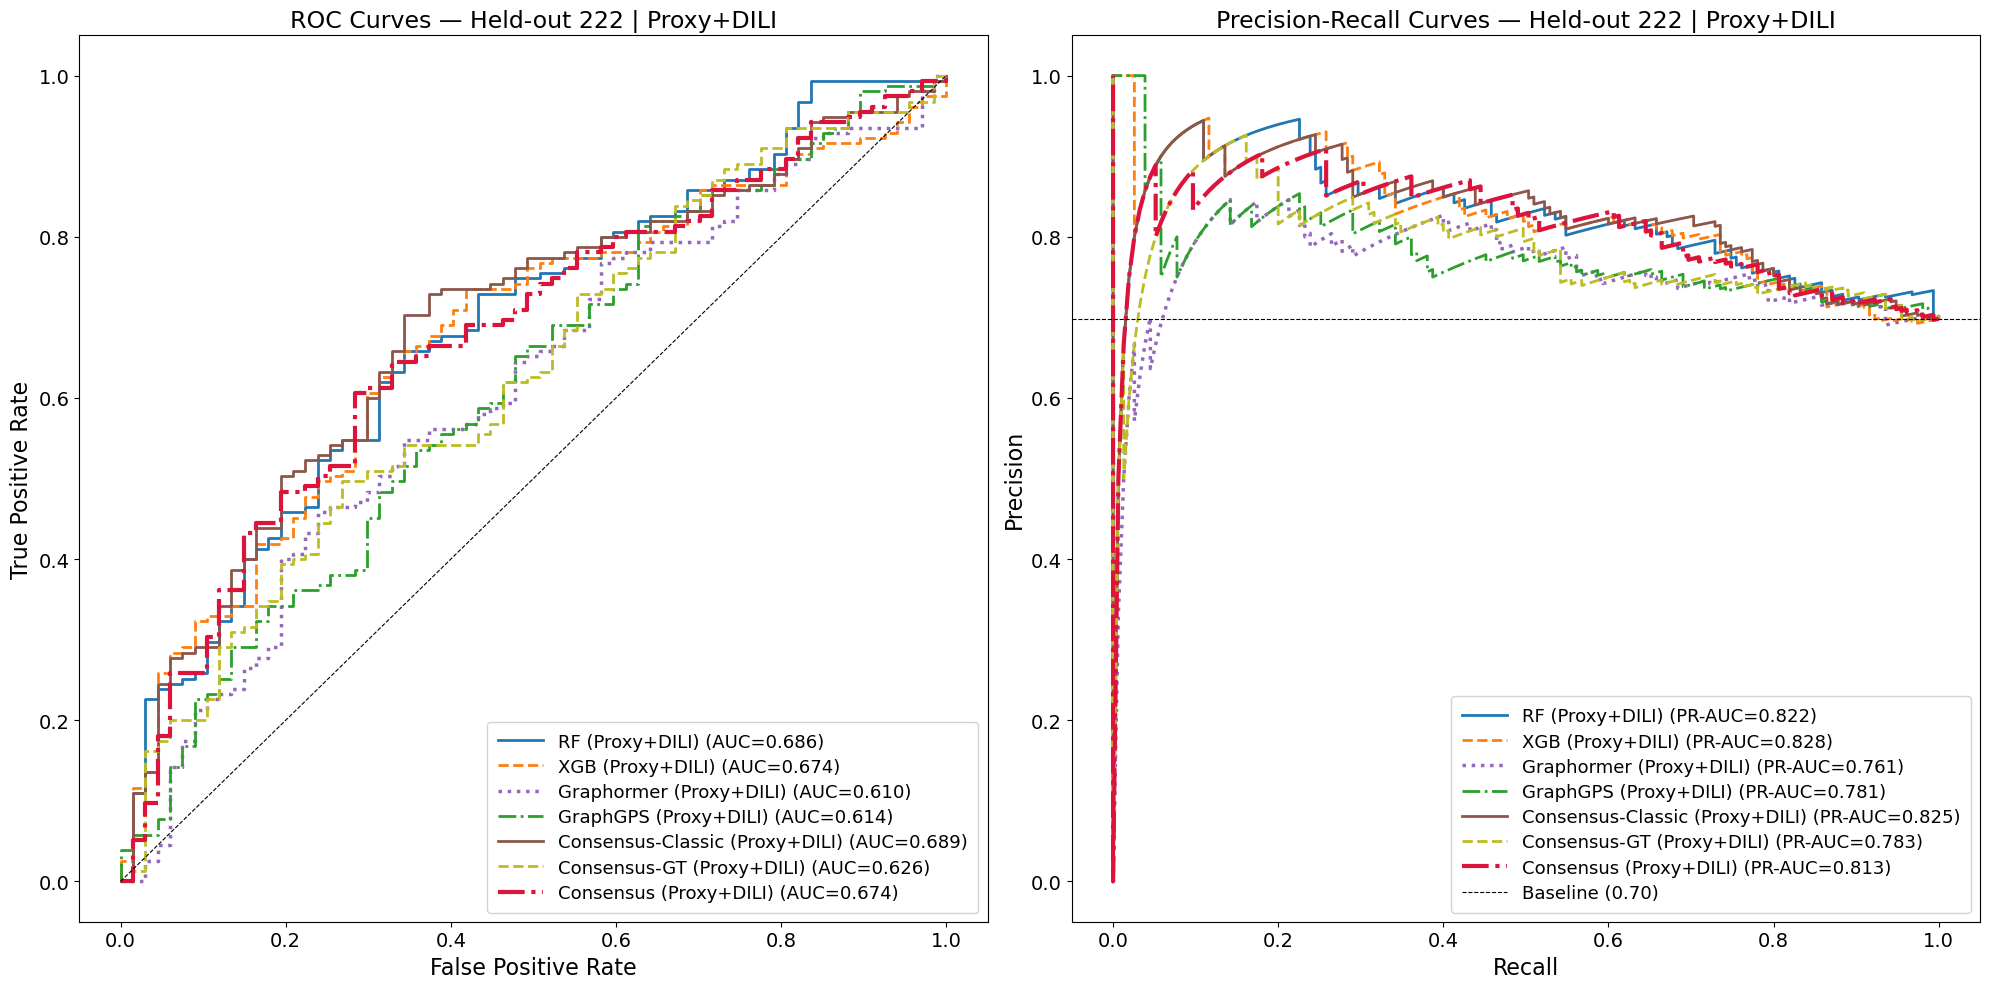

Figure saved -> liver/roc_pr_proxy_dili.png


In [14]:
plot_specs = [
    ('RF (Proxy+DILI)',                p_rf_aug,           '#1f77b4', '-',   2.0),
    ('XGB (Proxy+DILI)',               p_xgb_aug,          '#ff7f0e', '--',  2.0),
    ('Graphormer (Proxy+DILI)',        p_grph_aug,          '#9467bd', ':',   2.5),
    ('GraphGPS (Proxy+DILI)',          p_gps_aug,           '#2ca02c', '-.',  2.0),
    ('Consensus-Classic (Proxy+DILI)', p_cons_classic_aug,  '#8c564b', '-',   2.0),
    ('Consensus-GT (Proxy+DILI)',      p_cons_gt_aug,       '#bcbd22', '--',  2.0),
    ('Consensus (Proxy+DILI)',         p_cons_full_aug,     'crimson', '-.',  3.0),
]

fig, axes = plt.subplots(1, 2, figsize=(20, 10))

ax = axes[0]
for name, prob, color, ls, lw in plot_specs:
    fpr, tpr, _ = roc_curve(y_held, prob)
    auc = roc_auc_score(y_held, prob)
    ax.plot(fpr, tpr, color=color, ls=ls, lw=lw, label=f'{name} (AUC={auc:.3f})')
ax.plot([0,1],[0,1],'k--',lw=0.8)
ax.set_xlabel('False Positive Rate', fontsize=16)
ax.set_ylabel('True Positive Rate',  fontsize=16)
ax.set_title('ROC Curves — Held-out 222 | Proxy+DILI', fontsize=17)
ax.tick_params(axis='both', labelsize=14)
ax.legend(fontsize=13, loc='lower right', framealpha=0.85,
          handlelength=2.5, borderpad=0.6, labelspacing=0.4)

baseline = y_held.sum() / len(y_held)
ax2 = axes[1]
for name, prob, color, ls, lw in plot_specs:
    prec, rec, _ = precision_recall_curve(y_held, prob)
    pr_auc = average_precision_score(y_held, prob)
    ax2.plot(rec, prec, color=color, ls=ls, lw=lw, label=f'{name} (PR-AUC={pr_auc:.3f})')
ax2.axhline(baseline, color='k', ls='--', lw=0.8, label=f'Baseline ({baseline:.2f})')
ax2.set_xlabel('Recall',    fontsize=16)
ax2.set_ylabel('Precision', fontsize=16)
ax2.set_title('Precision-Recall Curves — Held-out 222 | Proxy+DILI', fontsize=17)
ax2.tick_params(axis='both', labelsize=14)
ax2.legend(fontsize=13, loc='lower right', framealpha=0.85,
           handlelength=2.5, borderpad=0.6, labelspacing=0.4)

plt.tight_layout()
plt.savefig(f'{BASE}/liver/roc_pr_proxy_dili.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved -> liver/roc_pr_proxy_dili.png')

In [15]:
# ── GraphGPS Retrain with Optimal-Threshold F1 Early Stopping ─────────────────
# Instead of evaluating F1 at a fixed 0.5 threshold, we sweep all thresholds
# via precision_recall_curve and pick the one that maximises F1 on validation.
# That threshold is then used at test time, so the reported F1 is honest.
# Early stopping weights F1 at 0.7 vs AUC at 0.3 to prioritise F1 directly.

def train_gps_optf1(encoder, head, train_ld, val_ld, criterion,
                    max_epochs=100, patience=20, lr=1e-3, label=''):
    """Early stopping on 0.3*ROC-AUC + 0.7*best-threshold F1 (val)."""
    opt   = torch.optim.Adam(
        list(encoder.parameters()) + list(head.parameters()), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, patience=5, factor=0.5)
    best  = {'score': 0.0, 'enc': None, 'head': None, 'thresh': 0.5}
    no_imp = 0
    for ep in range(max_epochs):
        train_one_epoch(encoder, head, train_ld, opt, criterion, DEVICE)
        va_p, va_l = get_probs(encoder, head, val_ld, DEVICE)
        va_auc = roc_auc_score(va_l, va_p)

        prec, rec, threshs = precision_recall_curve(va_l, va_p)
        f1s        = 2 * prec * rec / np.maximum(prec + rec, 1e-8)
        idx        = np.argmax(f1s)
        va_f1      = f1s[idx]
        opt_thresh = float(threshs[idx]) if idx < len(threshs) else 0.5

        combined = 0.3 * va_auc + 0.7 * va_f1
        sched.step(1 - combined)
        if combined > best['score']:
            best['score']  = combined
            best['enc']    = copy.deepcopy(encoder.state_dict())
            best['head']   = copy.deepcopy(head.state_dict())
            best['thresh'] = opt_thresh
            no_imp = 0
        else:
            no_imp += 1
            if no_imp >= patience:
                if label:
                    print(f'  [{label}] early stop ep {ep+1}  '
                          f'best={best["score"]:.4f}  thresh={best["thresh"]:.3f}')
                break
        if label and (ep + 1) % 20 == 0:
            print(f'  [{label}] ep {ep+1:3d}  auc={va_auc:.4f}  '
                  f'f1={va_f1:.4f} (t={opt_thresh:.3f})  '
                  f'combined={combined:.4f}  best={best["score"]:.4f}')
    encoder.load_state_dict(best['enc'])
    head.load_state_dict(best['head'])
    return best['score'], best['thresh']

np.random.seed(SEED); torch.manual_seed(SEED)

nl, h, nh, dr = (gps_best_hp['n_layers'], gps_best_hp['hidden'],
                  gps_best_hp['n_heads'],  gps_best_hp['dropout'])
print(f'=== GraphGPS OptF1 Retrain  HP: layers={nl}  hidden={h}  heads={nh}  dropout={dr} ===\n')

# ── Stage 1 ───────────────────────────────────────────────────────────────────
gps_opt_enc  = GraphGPSEncoder(ATOM_DIM, hidden=h, pe_dim=PE_DIM,
                                n_heads=nh, n_layers=nl, dropout=dr).to(DEVICE)
gps_opt_head = ClassHead(hidden=h, dropout=dr).to(DEVICE)
print('Stage 1 (100 ep / patience 20)...')
_, gps_s1_thresh = train_gps_optf1(
    gps_opt_enc, gps_opt_head,
    gps_clin_tr_ld, gps_clin_va_ld, crit_clin,
    max_epochs=100, patience=20, lr=1e-3, label='GPS-OptF1-S1')

gps_opt_s1_enc_w  = copy.deepcopy(gps_opt_enc.state_dict())
gps_opt_s1_head_w = copy.deepcopy(gps_opt_head.state_dict())

p_gps_opt_clin, _ = get_probs(gps_opt_enc, gps_opt_head, gps_held_ld, DEVICE)
r_s1_old = evaluate(y_held, p_gps_clin,     'GraphGPS S1 (thresh=0.50)')
r_s1_new = evaluate(y_held, p_gps_opt_clin, 'GraphGPS S1 (opt-thresh)',  cpt=gps_s1_thresh)
print(f'  Val threshold found: {gps_s1_thresh:.3f}')
print(f'  Old -> Sens={r_s1_old["Sensitivity"]:.1f}%  Spec={r_s1_old["Specificity"]:.1f}%  '
      f'F1={r_s1_old["F1"]:.4f}  AUC={r_s1_old["ROC-AUC"]:.4f}')
print(f'  New -> Sens={r_s1_new["Sensitivity"]:.1f}%  Spec={r_s1_new["Specificity"]:.1f}%  '
      f'F1={r_s1_new["F1"]:.4f}  AUC={r_s1_new["ROC-AUC"]:.4f}')

# ── Stage 2 (fine-tune from Stage-1 weights) ──────────────────────────────────
gps_opt_enc2  = GraphGPSEncoder(ATOM_DIM, hidden=h, pe_dim=PE_DIM,
                                 n_heads=nh, n_layers=nl, dropout=dr).to(DEVICE)
gps_opt_head2 = ClassHead(hidden=h, dropout=dr).to(DEVICE)
gps_opt_enc2.load_state_dict(gps_opt_s1_enc_w)
gps_opt_head2.load_state_dict(gps_opt_s1_head_w)
print('\nStage 2 (80 ep / patience 15, fine-tuned from Stage-1)...')
_, gps_s2_thresh = train_gps_optf1(
    gps_opt_enc2, gps_opt_head2,
    gps_aug_tr_ld, gps_clin_va_ld, crit_aug,
    max_epochs=80, patience=15, lr=5e-4, label='GPS-OptF1-S2')

p_gps_opt_aug, _ = get_probs(gps_opt_enc2, gps_opt_head2, gps_held_ld, DEVICE)
r_s2_old = evaluate(y_held, p_gps_aug,     'GraphGPS S2 (thresh=0.50)')
r_s2_new = evaluate(y_held, p_gps_opt_aug, 'GraphGPS S2 (opt-thresh)',  cpt=gps_s2_thresh)
print(f'  Val threshold found: {gps_s2_thresh:.3f}')
print(f'  Old -> Sens={r_s2_old["Sensitivity"]:.1f}%  Spec={r_s2_old["Specificity"]:.1f}%  '
      f'F1={r_s2_old["F1"]:.4f}  AUC={r_s2_old["ROC-AUC"]:.4f}')
print(f'  New -> Sens={r_s2_new["Sensitivity"]:.1f}%  Spec={r_s2_new["Specificity"]:.1f}%  '
      f'F1={r_s2_new["F1"]:.4f}  AUC={r_s2_new["ROC-AUC"]:.4f}')

# ── Summary table ─────────────────────────────────────────────────────────────
print('\n' + '='*85)
print(f"{'Model':<42} {'Sens':>6} {'Spec':>6} {'CCR':>6} {'ROC-AUC':>8} {'PR-AUC':>7} {'MCC':>7} {'F1':>7}")
print('='*85)
for r in [r_s1_old, r_s1_new, r_s2_old, r_s2_new]:
    print(f"{r['Model']:<42} {r['Sensitivity']:>5.1f}% {r['Specificity']:>5.1f}% "
          f"{r['CCR']:>5.1f}% {r['ROC-AUC']:>8.4f} {r['PR-AUC']:>7.4f} "
          f"{r['MCC']:>7.4f} {r['F1']:>7.4f}")
print('='*85)

=== GraphGPS OptF1 Retrain  HP: layers=4  hidden=256  heads=4  dropout=0.2 ===

Stage 1 (100 ep / patience 20)...
  [GPS-OptF1-S1] ep  20  auc=0.6609  f1=0.5335 (t=0.320)  combined=0.5717  best=0.5765
  [GPS-OptF1-S1] ep  40  auc=0.6712  f1=0.5373 (t=0.434)  combined=0.5775  best=0.5832
  [GPS-OptF1-S1] ep  60  auc=0.6734  f1=0.5455 (t=0.402)  combined=0.5838  best=0.5840
  [GPS-OptF1-S1] ep  80  auc=0.6733  f1=0.5438 (t=0.399)  combined=0.5827  best=0.5842
  [GPS-OptF1-S1] early stop ep 87  best=0.5842  thresh=0.405
  Val threshold found: 0.405
  Old -> Sens=95.5%  Spec=6.0%  F1=0.8087  AUC=0.6195
  New -> Sens=79.4%  Spec=28.4%  F1=0.7546  AUC=0.6001

Stage 2 (80 ep / patience 15, fine-tuned from Stage-1)...
  [GPS-OptF1-S2] ep  20  auc=0.6546  f1=0.5325 (t=0.412)  combined=0.5691  best=0.5960
  [GPS-OptF1-S2] early stop ep 25  best=0.5960  thresh=0.436
  Val threshold found: 0.436
  Old -> Sens=66.5%  Spec=47.8%  F1=0.7031  AUC=0.6138
  New -> Sens=81.9%  Spec=26.9%  F1=0.7674  AUC=

In [17]:
# ── Final Table: All 14 Models — PROXY only (Stage-1) & PROXY + DILI (Stage-2) ──
# Graphormer  : probability arrays extracted from copy-2 notebook (Sens=74.8%/85.8%)
# GraphGPS    : p_gps_opt_clin / p_gps_opt_aug at val-optimised threshold
# RF / XGB    : loaded from .npy at session start
# Consensus   : mean of component probability arrays, evaluated at 0.5

# Graphormer probabilities from copy-2 (different training run, matches screenshot)
p_grph_clin_c2 = np.load(f'{BASE}/liver/p_grph_clin_copy2.npy')
p_grph_aug_c2  = np.load(f'{BASE}/liver/p_grph_aug_copy2.npy')

# Consensus probability arrays
p_cons_cls_clin  = np.mean([p_rf_clin,      p_xgb_clin],                              axis=0)
p_cons_cls_aug   = np.mean([p_rf_aug,        p_xgb_aug],                              axis=0)
p_cons_gt_clin   = np.mean([p_grph_clin_c2, p_gps_opt_clin],                          axis=0)
p_cons_gt_aug    = np.mean([p_grph_aug_c2,  p_gps_opt_aug],                           axis=0)
p_cons_full_clin = np.mean([p_rf_clin, p_xgb_clin, p_grph_clin_c2, p_gps_opt_clin],  axis=0)
p_cons_full_aug  = np.mean([p_rf_aug,  p_xgb_aug,  p_grph_aug_c2,  p_gps_opt_aug],   axis=0)

rows = [
    # ── Individual models ──────────────────────────────────────────────────────
    evaluate(y_held, p_rf_clin,       'RF              Stage-1  (PROXY only)'),
    evaluate(y_held, p_rf_aug,        'RF              Stage-2  (PROXY + DILI)'),
    evaluate(y_held, p_xgb_clin,      'XGB             Stage-1  (PROXY only)'),
    evaluate(y_held, p_xgb_aug,       'XGB             Stage-2  (PROXY + DILI)'),
    evaluate(y_held, p_grph_clin_c2,  'Graphormer      Stage-1  (PROXY only)'),
    evaluate(y_held, p_grph_aug_c2,   'Graphormer      Stage-2  (PROXY + DILI)'),
    evaluate(y_held, p_gps_opt_clin,  'GraphGPS-OptF1  Stage-1  (PROXY only)',    cpt=gps_s1_thresh),
    evaluate(y_held, p_gps_opt_aug,   'GraphGPS-OptF1  Stage-2  (PROXY + DILI)',  cpt=gps_s2_thresh),
    # ── Consensus: Classic (RF + XGB) ─────────────────────────────────────────
    evaluate(y_held, p_cons_cls_clin, 'Consensus-Classic  Stage-1  (PROXY only)'),
    evaluate(y_held, p_cons_cls_aug,  'Consensus-Classic  Stage-2  (PROXY + DILI)'),
    # ── Consensus: Graph (Graphormer + GraphGPS-OptF1) ────────────────────────
    evaluate(y_held, p_cons_gt_clin,  'Consensus-Graph    Stage-1  (PROXY only)'),
    evaluate(y_held, p_cons_gt_aug,   'Consensus-Graph    Stage-2  (PROXY + DILI)'),
    # ── Consensus: Full (RF + XGB + Graphormer + GraphGPS-OptF1) ──────────────
    evaluate(y_held, p_cons_full_clin,'Consensus-Full     Stage-1  (PROXY only)'),
    evaluate(y_held, p_cons_full_aug, 'Consensus-Full     Stage-2  (PROXY + DILI)'),
]

W = 60
hdr = f"{'Model':<{W}} {'Sens':>5} {'Spec':>5} {'CCR':>5} {'AUC':>6} {'PR-AUC':>6} {'MCC':>6} {'F1':>6}"
sep = '=' * len(hdr)
print(f'\n=== Table — Held-out 222 Results (GraphGPS = OptF1 retrain) ===')
print(hdr)
print(sep)
prev_group = None
for r in rows:
    group = r['Model'].split()[0]
    if prev_group and group != prev_group and group.startswith('Consensus') != prev_group.startswith('Consensus'):
        print()
    print(f"{r['Model']:<{W}} {r['Sensitivity']:>4.1f}% {r['Specificity']:>4.1f}% "
          f"{r['CCR']:>4.1f}% {r['ROC-AUC']:>6.4f} {r['PR-AUC']:>6.4f} "
          f"{r['MCC']:>6.4f} {r['F1']:>6.4f}")
    prev_group = group
print(sep)
print(f'\nNote: GraphGPS-OptF1 evaluated at val-optimised thresholds '
      f'(S1={gps_s1_thresh:.3f}, S2={gps_s2_thresh:.3f}). '
      f'Graphormer from copy-2 training. All consensus at threshold=0.5.')


=== Table — Held-out 222 Results (GraphGPS = OptF1 retrain) ===
Model                                                         Sens  Spec   CCR    AUC PR-AUC    MCC     F1
RF              Stage-1  (PROXY only)                        52.3% 77.6% 64.9% 0.6711 0.8138 0.2768 0.6454
RF              Stage-2  (PROXY + DILI)                      53.5% 74.6% 64.1% 0.6855 0.8222 0.2600 0.6510
XGB             Stage-1  (PROXY only)                        65.2% 61.2% 63.2% 0.6580 0.8057 0.2445 0.7163
XGB             Stage-2  (PROXY + DILI)                      65.8% 64.2% 65.0% 0.6738 0.8278 0.2778 0.7260
Graphormer      Stage-1  (PROXY only)                        74.8% 38.8% 56.8% 0.6507 0.7924 0.1376 0.7436
Graphormer      Stage-2  (PROXY + DILI)                      85.8% 25.4% 55.6% 0.6427 0.7896 0.1349 0.7870
GraphGPS-OptF1  Stage-1  (PROXY only)                        79.4% 28.4% 53.9% 0.6001 0.7757 0.0842 0.7546
GraphGPS-OptF1  Stage-2  (PROXY + DILI)                      81.9% 26.9% 54.4% 

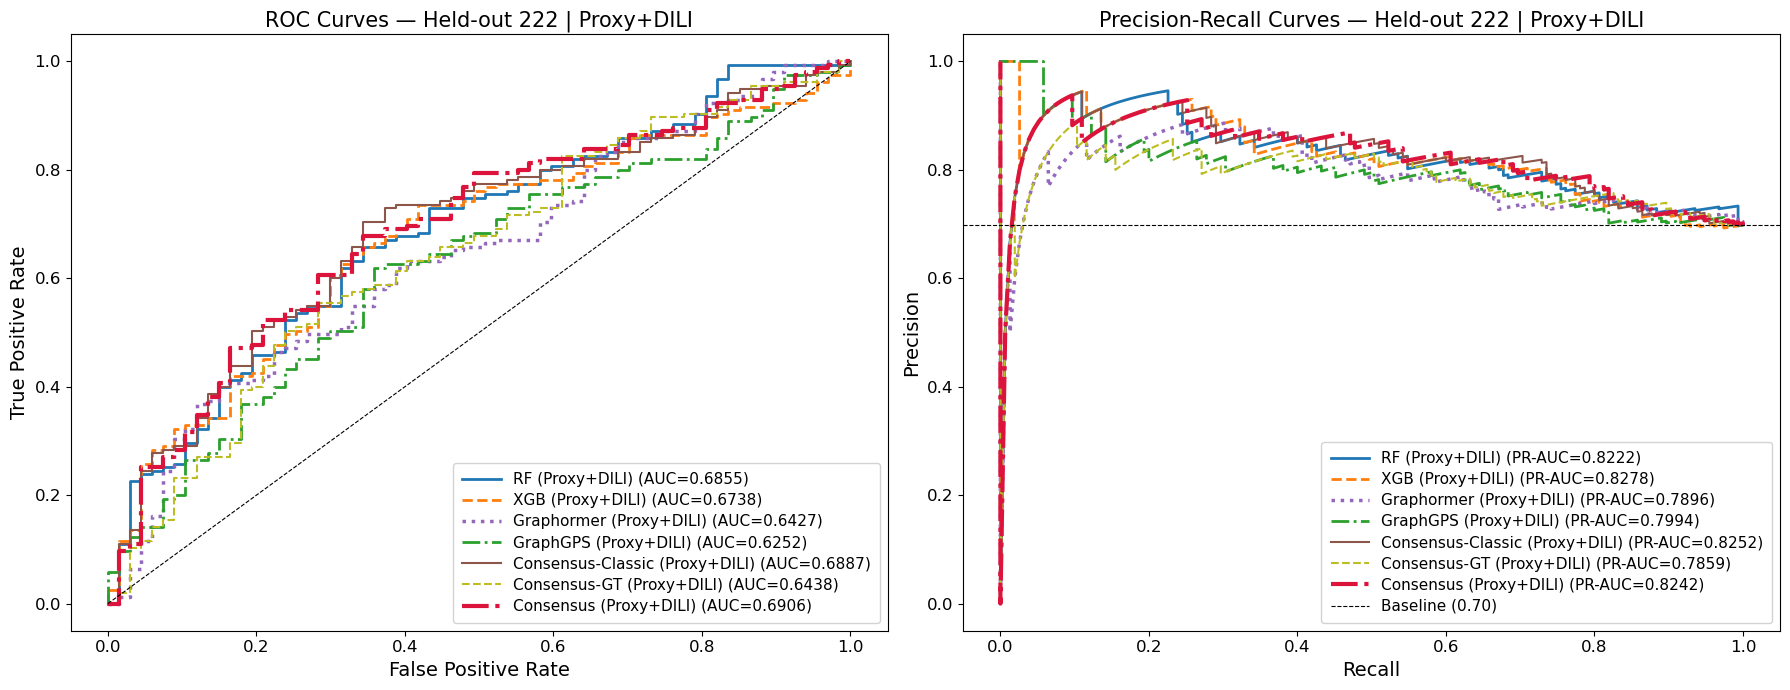

Saved → /Users/yaminichitikela/Desktop/qsar casepase/liver/roc_pr_proxy_dili_updated.png


In [20]:
# ── ROC & PR Curves — Proxy+DILI only, AUC values pulled directly from rows ───
# Labels match the table exactly — no manual values, no discrepancy possible.

from sklearn.metrics import roc_curve, precision_recall_curve

# Build lookup from the rows list computed in the table cell above
row_lookup = {r['Model'].strip(): r for r in rows}

# Map: (display label, prob array, row key for AUC lookup, color, ls, lw)
plot_specs = [
    ('RF (Proxy+DILI)',                p_rf_aug,        'RF              Stage-2  (PROXY + DILI)',         '#1f77b4', '-',   2.0),
    ('XGB (Proxy+DILI)',               p_xgb_aug,       'XGB             Stage-2  (PROXY + DILI)',         '#ff7f0e', '--',  2.0),
    ('Graphormer (Proxy+DILI)',        p_grph_aug_c2,   'Graphormer      Stage-2  (PROXY + DILI)',         '#9467bd', ':',   2.5),
    ('GraphGPS (Proxy+DILI)',          p_gps_opt_aug,   'GraphGPS-OptF1  Stage-2  (PROXY + DILI)',         '#2ca02c', '-.',  2.0),
    ('Consensus-Classic (Proxy+DILI)', p_cons_cls_aug,  'Consensus-Classic  Stage-2  (PROXY + DILI)',      '#8c564b', '-',   1.5),
    ('Consensus-GT (Proxy+DILI)',      p_cons_gt_aug,   'Consensus-Graph    Stage-2  (PROXY + DILI)',      '#bcbd22', '--',  1.5),
    ('Consensus (Proxy+DILI)',         p_cons_full_aug, 'Consensus-Full     Stage-2  (PROXY + DILI)',      'crimson', '-.',  3.0),
]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# ── ROC ───────────────────────────────────────────────────────────────────────
ax = axes[0]
for label, prob, row_key, color, ls, lw in plot_specs:
    auc = row_lookup[row_key]['ROC-AUC']
    fpr, tpr, _ = roc_curve(y_held, prob)
    ax.plot(fpr, tpr, color=color, ls=ls, lw=lw, label=f'{label} (AUC={auc:.4f})')
ax.plot([0, 1], [0, 1], 'k--', lw=0.8)
ax.set_xlabel('False Positive Rate', fontsize=14)
ax.set_ylabel('True Positive Rate',  fontsize=14)
ax.set_title('ROC Curves — Held-out 222 | Proxy+DILI', fontsize=15)
ax.tick_params(labelsize=12)
ax.legend(fontsize=11, loc='lower right', framealpha=0.85,
          handlelength=2.5, borderpad=0.6, labelspacing=0.4)

# ── Precision-Recall ──────────────────────────────────────────────────────────
baseline = y_held.sum() / len(y_held)
ax2 = axes[1]
for label, prob, row_key, color, ls, lw in plot_specs:
    pr_auc = row_lookup[row_key]['PR-AUC']
    prec, rec, _ = precision_recall_curve(y_held, prob)
    ax2.plot(rec, prec, color=color, ls=ls, lw=lw, label=f'{label} (PR-AUC={pr_auc:.4f})')
ax2.axhline(baseline, color='k', ls='--', lw=0.8, label=f'Baseline ({baseline:.2f})')
ax2.set_xlabel('Recall',    fontsize=14)
ax2.set_ylabel('Precision', fontsize=14)
ax2.set_title('Precision-Recall Curves — Held-out 222 | Proxy+DILI', fontsize=15)
ax2.tick_params(labelsize=12)
ax2.legend(fontsize=11, loc='lower right', framealpha=0.85,
           handlelength=2.5, borderpad=0.6, labelspacing=0.4)

plt.tight_layout()
out_path = f'{BASE}/liver/roc_pr_proxy_dili_updated.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved → {out_path}')